In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)

**a. Pemeriksaan Awal & Penghapusan Duplikat**

In [6]:
# Membaca datset mentah nasabah
df_nasabah = pd.read_csv('nasabah_raw.csv')

# 1. Memeriksa dimensi awal (.shape) dan informasi tipe data tiap kolom (.info())
print("Dimensi awal dataset:", df_nasabah.shape)
print("\nInformasi tipe data:")
df_nasabah.info()

# 2. Identifikasi jumlah data duplikat penuh & tampilkan sampel baros terduplikasi
jumlah_duplikat = df_nasabah.duplicated().sum()
print(f"\nJumlah data duplikat penuh: {jumlah_duplikat} baris")

print("\nSampel baris terduplikasi:")
print(df_nasabah[df_nasabah.duplicated(keep=False)].sort_index().head(6))

# Hapus seluruh data duplikat penuh
df_nasabah = df_nasabah.drop_duplicates().reset_index(drop=True)

# 3. Sisa baris data setelah tahap ini
print(f"\nDimensi setelah penghapusan duplikat: {df_nasabah.shape}")
print(f"Sisa baris data: {df_nasabah.shape[0]} baris")

Dimensi awal dataset: (1045, 9)

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

Jumlah data duplikat penuh: 45 baris

Sampel baris terduplikasi:
    ID_Pelanggan  Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Bekerja_Thn  \
59     CUST-1060  53.0          14765000.0        4

**Analisis:**
* Dataset awal `nasabah_raw.csv` memiliki dimensi **1.045 baris dan 9 kolom**, dengan **45 baris duplikat penuh**.
* Setelah duplikat dihapus menggunakan `drop_duplicates()`, sisa data yang valid adalah **1.000 baris**. Penghapusan ini mencegah bias perhitungan statistik dan menghindari *overfitting* pada model Machine Learning akibat data nasabah yang tercatat ganda.

**b. Penanganan Kesalahan Data**

In [9]:
# 1. Periksa nilai unik Status_Pernikahan dan bersihkan format teks
print("Nilai unik Status_Pernikahan sebelum dibersihkan:", df_nasabah['Status_Pernikahan'].unique())

df_nasabah['Status_Pernikahan'] = (
    df_nasabah['Status_Pernikahan']
    .str.strip()          # Menghapus spasi berlebihan diawal/akhir
    .str.capitalize()     # Menyeragamkan huruf kapital ('single' -> 'Single', 'MENIKAH' -> 'Menikah')
)

print("Nilai unik Status_Pernikahan setelah dibersihkan:", df_nasabah['Status_Pernikahan'].unique())

# 2. Pemeriksaan logis pada kolom Usia (rentang valid: 17-100 tahun)
anomali_usia = df_nasabah[(df_nasabah['Usia'] < 17) | (df_nasabah['Usia'] > 100)]
print(f"\nJumlah data dengan usia tidak logis: {len(anomali_usia)} baris")
print(anomali_usia[['ID_Pelanggan', 'Usia']].head())

# Ubah nilai yang melanggar batas kewajaran logis menjadi NaN
df_nasabah.loc[(df_nasabah['Usia'] < 17) | (df_nasabah['Usia'] > 100), 'Usia'] = np.nan

Nilai unik Status_Pernikahan sebelum dibersihkan: ['Menikah' 'Single' 'Cerai']
Nilai unik Status_Pernikahan setelah dibersihkan: ['Menikah' 'Single' 'Cerai']

Jumlah data dengan usia tidak logis: 35 baris
   ID_Pelanggan   Usia
4     CUST-1005   -5.0
28    CUST-1029   -5.0
33    CUST-1034   -5.0
49    CUST-1050  350.0
74    CUST-1075  350.0


**Analisis & Jawaban Pertanyaan:**
* Pembersihan format teks pada `Status_Pernikahan` menyatukan kategori yang terduplikasi akibat spasi dan perbedaan kapitalisasi menjadi 3 kategori bersih (`Menikah`, `Single`, `Cerai`). Sementara pada kolom `Usia`, ditemukan **35 baris anomali** (bernilai `-5` dan `350` tahun) yang diubah menjadi `NaN`.
* **Mengapa koreksi kesalahan nilai pada `Usia` harus dilakukan sebelum menghitung nilai rata-rata (*mean*) atau *median*?**
  Karena nilai anomali ekstrem (seperti `-5` atau `350`) akan menarik dan mendistorsi nilai *mean* secara drastis serta menggeser titik tengah distribusi (*median*). Jika *mean* atau *median* dihitung sebelum anomali diubah menjadi `NaN`, proses imputasi nantinya akan mengisi data kosong menggunakan angka statistik yang sudah bias akibat kesalahan input.

**c. Integrasi Data**

In [11]:
# Membaca data historis perbankan eksternal
df_kredit = pd.read_csv('data_kredit_eksternal.csv')

# 1 & 2. Penggabungan dengan metode Left Join bberdasarkan kunci ID_Pelanggan
df_merged = pd.merge(
    df_nasabah,
    df_kredit,
    on='ID_Pelanggan',
    how='left'
)

# 3. Tampilkan dimensi dataset setelah proses penggabungan
print("Dimensi dataset setelah proses penggabungan (Left Join):", df_merged.shape)

Dimensi dataset setelah proses penggabungan (Left Join): (1000, 11)


**Analisis:**
* Metode `left join` digunakan agar seluruh **1.000 baris data nasabah utama** tetap terjaga tanpa ada yang terbuang meskipun tidak ditemukan pasangannya pada tabel `data_kredit_eksternal.csv` (yang hanya berisi 850 baris). Dimensi dataset setelah penggabungan bertambah menjadi **1.000 baris dan 11 kolom**.

**d. Penanganan Data yang Hilang (Missing Values)**

In [13]:
# 1. Tampilkan presentase missing values untuk setiap kolom
missing_persen = (df_merged.isnull().sum() / len(df_merged))* 100
print("Presentase missing values per Kolom (%):")
print(missing_persen.round(2))

# 2. Tangani missing value sesuai strategi
# a. Kolom numerik kontinu -> gunakan nilai median
kolom_kontinu = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn', 'Pendapatan_Tahunan_Est']
for col in kolom_kontinu:
    df_merged[col] = df_merged[col].fillna(df_merged[col].median())

# b. Kolom diskrit (Jumlah_Kartu_Kredit) -> isi dengan 0
df_merged['Jumlah_Kartu_Kredit'] = df_merged['Jumlah_Kartu_Kredit'].fillna(0)

# c. Kolom kategorikal -> gunakan nilai modus
kolom_kategorikal = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
for col in kolom_kategorikal:
    modus_val = df_merged[col].mode()[0]
    df_merged[col] = df_merged[col].fillna(modus_val)

# 3. Pastikan tidak ada lagi missing value yang tersisa
print("\nTotal missing values tersisa:", df_merged.isnull().sum().sum())

Presentase missing values per Kolom (%):
ID_Pelanggan                0.0
Usia                        3.5
Pendapatan_Bulanan          6.0
Skor_Kredit                 0.0
Lama_Bekerja_Thn            4.0
Status_Pernikahan           0.0
Tingkat_Pendidikan          3.5
Status_Default              0.0
Pendapatan_Tahunan_Est      6.0
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
dtype: float64

Total missing values tersisa: 0


**Analisis:**
* Variabel numerik kontinu (`Usia`, `Pendapatan_Bulanan`, `Lama_Bekerja_Thn`, `Pendapatan_Tahunan_Est`) diimputasi dengan **median** karena lebih tahan (*robust*) terhadap nilai ekstrem dibandingkan *mean*.
* Kolom `Jumlah_Kartu_Kredit` (hilang 15%) diisi dengan **0** sesuai asumsi domain bisnis bahwa nasabah tidak memiliki kartu kredit, sedangkan kolom kategorikal diisi menggunakan **modus** (`Sarjana` dan `Tidak`). Setelah imputasi, sisa *missing values* adalah **0**.

**e. Penanganan Pencilan (Outlier Handling)**

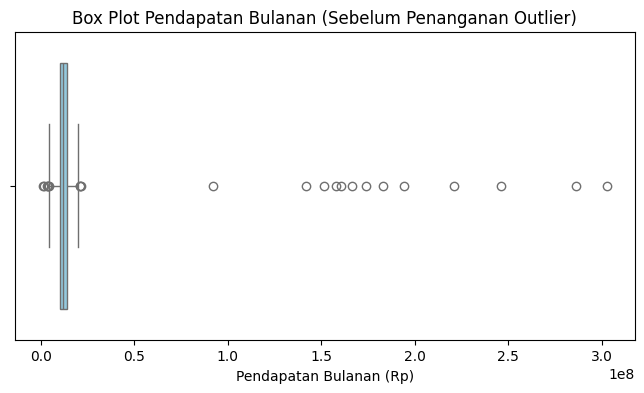

Q1          : Rp 10,192,000.00
Q3          : Rp 14,100,250.00
IQR         : Rp 3,908,250.00
Batas Bawah : Rp 4,329,625.00
Batas Atas  : Rp 19,962,625.00


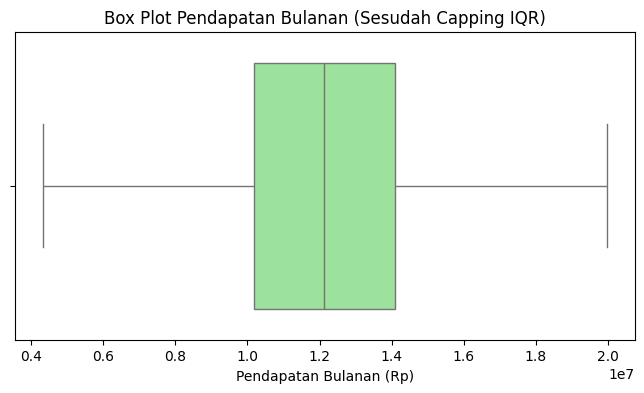

In [14]:
# 1. Buat visualisasi box plot untuk memeriksa sebaran nilai pada Pendapatan_Bulanan
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'], color='skyblue')
plt.title('Box Plot Pendapatan Bulanan (Sebelum Penanganan Outlier)')
plt.xlabel('Pendapatan Bulanan (Rp)')
plt.show()

# 2. Hitung ambang batas menggunakan metode Interquartile Range (IQR)
Q1 = df_merged['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_merged['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Q1          : Rp {Q1:,.2f}")
print(f"Q3          : Rp {Q3:,.2f}")
print(f"IQR         : Rp {IQR:,.2f}")
print(f"Batas Bawah : Rp {batas_bawah:,.2f}")
print(f"Batas Atas  : Rp {batas_atas:,.2f}")

# 3. Terapkan metode pembatasan (Capping) tanpa membuang baris data
df_merged['Pendapatan_Bulanan'] = np.clip(
    df_merged['Pendapatan_Bulanan'],
    a_min=batas_bawah,
    a_max=batas_atas
)

# Visualisasi ulang setelah pembatasan outlier
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'], color='lightgreen')
plt.title('Box Plot Pendapatan Bulanan (Sesudah Capping IQR)')
plt.xlabel('Pendapatan Bulanan (Rp)')
plt.show()

**Analisis & Jawaban Pertanyaan:**
* Berdasarkan perhitungan IQR, diperoleh **Batas Bawah = Rp 4.329.625** dan **Batas Atas = Rp 19.962.625**. Nilai ekstrem di luar rentang tersebut dibatasi (*capping*) ke ambang batasnya.
* **Apa konsekuensi negatif jika membuang baris (*drop rows*) yang mengandung *outlier* dibandingkan melakukan pembatasan pada dataset ini?**
  1. **Kehilangan Informasi Fitur Lain:** Menghapus 22 baris berarti membuang informasi berharga pada variabel lain milik nasabah tersebut (seperti `Skor_Kredit` dan riwayat gagal bayar).
  2. **Memperparah *Class Imbalance*:** Pada deteksi gagal bayar (`Status_Default`), nasabah gagal bayar merupakan kelas minoritas. Membuang baris berisiko menghilangkan sampel gagal bayar yang langka sehingga performa prediksi model menurun.
  3. **Bias Representasi Populasi:** Nasabah dengan penghasilan sangat tinggi atau rendah memang ada di dunia nyata; membuangnya membuat model tidak mampu mengenali pola segmen nasabah tersebut saat diimplementasikan.

**f. Pengkodean Data Kategorikal (Categorical Encoding)**

In [15]:
df_encoded = df_merged.copy()

# 1. Ordinal Encoding pada Tingkat_Pendidikan: SMA (1), Sarjana (2), Magister (3)
urutan_pendidikan = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_encoded['Tingkat_Pendidikan_Encoded'] = df_encoded['Tingkat_Pendidikan'].map(urutan_pendidikan)

# 2. Binary Mapping (0 dan 1) pada kolom biner Pernah_Gagal_Bayar_Lain
mapping_biner = {'Tidak': 0, 'Ya': 1}
df_encoded['Pernah_Gagal_Bayar_Lain_Encoded'] = df_encoded['Pernah_Gagal_Bayar_Lain'].map(mapping_biner)

# 3. One-Hot Encoding pada Status_Pernikahan (drop_first=True)
status_dummies = pd.get_dummies(
    df_encoded['Status_Pernikahan'],
    prefix='Status_Pernikahan',
    drop_first=True,
    dtype=int
)
df_encoded = pd.concat([df_encoded, status_dummies], axis=1)

# 4. Hapus kolom-kolom teks asli serta kolom identifier (ID_Pelanggan)
kolom_dihapus = ['ID_Pelanggan', 'Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain', 'Status_Pernikahan']
df_encoded = df_encoded.drop(columns=kolom_dihapus)

print("Kolom setelah Categorical Encoding:")
print(df_encoded.columns.tolist())

Kolom setelah Categorical Encoding:
['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Jumlah_Kartu_Kredit', 'Tingkat_Pendidikan_Encoded', 'Pernah_Gagal_Bayar_Lain_Encoded', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


**Analisis:**
* *Ordinal Encoding* digunakan pada `Tingkat_Pendidikan` untuk mempertahankan urutan tingkatan jenjang pendidikan (`SMA < Sarjana < Magister`).
* *One-Hot Encoding* dengan `drop_first=True` pada `Status_Pernikahan` mencegah *dummy variable trap* (multikolinearitas sempurna antar fitur dummy), sedangkan `ID_Pelanggan` dihapus karena hanya berupa pengenal unik yang tidak memiliki pola prediktif.

**g. Penskalaan Fitur (Feature Scaling) & Penyimpanan Dataset Bersih**

In [16]:
# 1. Pisahkan fitur prediktor (X) dan target (y = Status_Default)
X = df_encoded.drop(columns=['Status_Default'])
y = df_encoded['Status_Default']

# 3a. Tampilkan ringkasan statistik (.describe()) 3 fitur numerik SEBELUM standarisasi
fitur_3 = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']
print("=== Ringkasan Statistik SEBELUM Standarisasi ===")
print(X[fitur_3].describe().round(2))

# 2. Lakukan transformasi Standardization (Z-score) pada seluruh variabel numerik
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 3b. Tampilkan ringkasan statistik (.describe()) 3 fitur numerik SESUDAH standarisasi
print("\n=== Ringkasan Statistik SESUDAH Standarisasi ===")
print(X_scaled[fitur_3].describe().round(2))

# Gabungkan kembali fitur yang sudah di-scale dengan target y
df_final = pd.concat([X_scaled, y.reset_index(drop=True)], axis=1)

# 4. Simpan hasil akhir ke format CSV dengan nama clean_nasabah_final.csv
df_final.to_csv('clean_nasabah_final.csv', index=False)
print("\nDataset bersih berhasil disimpan sebagai 'clean_nasabah_final.csv' dengan dimensi:", df_final.shape)

=== Ringkasan Statistik SEBELUM Standarisasi ===
          Usia  Pendapatan_Bulanan  Lama_Bekerja_Thn
count  1000.00             1000.00           1000.00
mean     40.08         12127496.75             12.95
std      11.58          3062611.27              6.69
min      20.00          4329625.00              1.00
25%      30.00         10192000.00              8.00
50%      41.00         12132000.00             13.00
75%      50.00         14100250.00             19.00
max      59.00         19962625.00             24.00

=== Ringkasan Statistik SESUDAH Standarisasi ===
          Usia  Pendapatan_Bulanan  Lama_Bekerja_Thn
count  1000.00             1000.00           1000.00
mean     -0.00                0.00             -0.00
std       1.00                1.00              1.00
min      -1.74               -2.55             -1.79
25%      -0.87               -0.63             -0.74
50%       0.08                0.00              0.01
75%       0.86                0.64              0.91


**Analisis:**
* Setelah dilakukan transformasi *Standardization (Z-score)* menggunakan `StandardScaler`, seluruh fitur numerik memiliki skala yang seragam dengan nilai rata-rata (`mean`) $\approx 0$ dan standar deviasi (`std`) $\approx 1$.
* Penskalaan ini penting agar fitur dengan satuan jutaan (seperti `Pendapatan_Bulanan`) tidak mendominasi fitur berskala puluhan (seperti `Usia` atau `Lama_Bekerja_Thn`) saat melatih algoritma Machine Learning. Dataset akhir siap pakai telah disimpan ke berkas **`clean_nasabah_final.csv`** (1.000 baris × 11 kolom).